# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Nguồn đầu vào (2 chế độ):** **1. Link TikTok** (Chuẩn bị dữ liệu: tự tải video/ảnh, crawl comment + reply và phân tích nội dung video lưu vào `data/<post_id>/`) hoặc **2. Thư mục đã chuẩn bị sẵn** (`data/<post_id>/` chứa `raw_comments.csv`, video/ảnh & `media_context.json`).
- **Chuẩn bị dữ liệu & Giai đoạn 1 (`gemma4-e2b-opt` + Whisper):** Trích khung hình có mốc thời gian (`768px`, tự động 2-pass cho slideshow dài) + lời thoại Whisper + caption thành JSON Evidence-First (11 trường) và lưu vào `data/<post_id>/media_context.json` để tái sử dụng cho Giai đoạn 2–3 mà không cần chạy lại Gemma 4.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu có ngữ cảnh (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), bảo vệ thực thể video không bị lọc nhầm, lọc nhiễu, tách từ `underthesea` và tính độ liên quan chủ đề (`is_on_topic`, `context_relevance`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):** Giữ chuẩn NLP đánh giá cảm xúc từng bình luận (`TF-IDF NB/LR/SVM`, `Lexicon`, `ViSoBERT`, `PhoBERT`, `Twitter-RoBERTa`, `Emotion 7 cung bậc`) kết hợp tầng Context Alignment (`context_alignment` xuất tại `detailed_model_outputs.csv`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`, mặc định TẮT):** Khi bật `RUN_AI_AUDIT = True`, `gemma4-e2b-opt` thẩm định các ca mỉa mai sâu & kết quả Giai đoạn 3 dựa trên `media_context.json`; xuất 6 tệp gọn ra `outputs/<run_name>/` (`final_results.csv` sắp theo likes, `detailed_model_outputs.csv`, `filtered_noise.csv`, `model_comparison.csv`, `report.json`, `dashboard.png`).

> Lưu ý: Chỉ cần khởi động container Ollama `gemma4-e2b` khi trích xuất mới `media_context.json` ở Giai đoạn 1 hoặc khi bật Giai đoạn 4 (`RUN_AI_AUDIT = True`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard
# Nhật anh project
# === TÙY CHỌN GÁN CỨNG (để None nếu muốn notebook hỏi tương tác khi chạy) ===
INPUT_MODE = None            # None (hỏi trực tiếp) | "url" | "folder"
TIKTOK_URL = ""
INPUT_DIR = None             # Đường dẫn thư mục đã chuẩn bị sẵn (vd: "data/7711719899852295445") cho chế độ "folder"
RUN_MEDIA_ANALYSIS = True    # True = dùng/trích xuất media_context.json; False = bỏ qua ngữ cảnh video
FORCE_REANALYZE_MEDIA = False # True = ép Gemma 4 + Whisper phân tích lại dù đã có media_context.json
PREPARE_ONLY = False         # True = chỉ Chuẩn bị dữ liệu vào data/<post_id>/ rồi dừng
RUN_AI_AUDIT = False         # Mặc định TẮT Giai đoạn 4 (đặt True để bật Gemma 4 thẩm định ca mỉa mai sâu, hoặc None để hỏi)

# === CHỌN NGUỒN ĐẦU VÀO ===
if INPUT_MODE is None:
    print("Chọn nguồn dữ liệu đầu vào:")
    print("  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)")
    print("  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)")
    _choice = input("Nhập lựa chọn [1/2, mặc định 1]: ").strip() or "1"
    INPUT_MODE = {"1": "url", "2": "folder"}.get(_choice, "url")

if INPUT_MODE == "url":
    if not TIKTOK_URL:
        TIKTOK_URL = input("Nhập link video/ảnh TikTok: ").strip().strip('"\'')
elif INPUT_MODE == "folder":
    if not INPUT_DIR:
        INPUT_DIR = input("Nhập đường dẫn thư mục (vd: data/7711719899852295445): ").strip().strip('"\'')
else:
    raise ValueError(f"INPUT_MODE không hợp lệ: {INPUT_MODE} (chỉ hỗ trợ 'url' hoặc 'folder').")

# === TÙY CHỌN GIAI ĐOẠN 4 (THẨM ĐỊNH BẰNG AI — MẶC ĐỊNH TẮT) ===
if RUN_AI_AUDIT is None:
    _ans = input("Có chạy Giai đoạn 4 (dùng AI Gemma 4 thẩm định ca mỉa mai sâu & kết quả Giai đoạn 3) không? [y/N, mặc định N]: ").strip().lower()
    RUN_AI_AUDIT = True if _ans in {"y", "yes", "c", "co", "có", "1"} else False

# === CẤU HÌNH HỆ THỐNG ===
ENABLE_AUDIO = True
AUDIT_LIMIT = None             # None = chấm 100% bình luận hợp lệ khi bật AI Audit
MAX_COMMENTS = 2000            # Số lượng bình luận tối đa cần thu thập (cả comment + reply)
INCLUDE_REPLIES = True         # Thu thập cả bình luận trả lời (reply)
MAX_REPLIES_PER_COMMENT = None # None = lấy toàn bộ reply tới khi chạm MAX_COMMENTS
DEDUPLICATE_STATS = False      # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")        # Nơi lưu toàn bộ dữ liệu chuẩn bị đầu vào (video, comments, media_context.json)
OUTPUT_DIR = Path("outputs")   # Nơi xuất kết quả cuối cùng sau xử lý

print(f"-> Chế độ đầu vào: {INPUT_MODE} | Media Context: {RUN_MEDIA_ANALYSIS} | Prepare Only: {PREPARE_ONLY} | Giai đoạn 4 (AI Audit): {RUN_AI_AUDIT}")

Chọn nguồn dữ liệu đầu vào:
  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)
  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)
-> Chế độ đầu vào: folder | Media Context: True | Prepare Only: False | Giai đoạn 4 (AI Audit): False


In [2]:
# === CHẠY TOÀN BỘ PIPELINE ===
if INPUT_MODE == "url" and not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link TikTok vào biến TIKTOK_URL.")
if INPUT_MODE == "folder" and not INPUT_DIR:
    raise ValueError("Vui lòng nhập đường dẫn thư mục vào biến INPUT_DIR.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL if INPUT_MODE == "url" else None,
    input_dir=INPUT_DIR if INPUT_MODE == "folder" else None,
    enable_audio=ENABLE_AUDIO,
    run_media_analysis=RUN_MEDIA_ANALYSIS,
    force_reanalyze_media=FORCE_REANALYZE_MEDIA,
    prepare_only=PREPARE_ONLY,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    include_replies=INCLUDE_REPLIES,
    max_replies_per_comment=MAX_REPLIES_PER_COMMENT,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
if report.get("prepare_only"):
    print(f"-> Đã chuẩn bị xong dữ liệu tại: {report.get('data_dir')}")
    print(f"-> Tệp media_context.json: {report.get('media_context_path')}")
else:
    print(f"-> Kết quả xử lý xuất tại: {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Chuẩn bị dữ liệu] Đã nạp nội dung video/ảnh có sẵn từ data\7711719899852295445\media_context.json (bỏ qua chạy lại Gemma 4).
[Giai đoạn 2] Lọc nhiễu, nhận diện ngôn ngữ (VI/EN) & đối chiếu ngữ cảnh (200 bình luận)...
  -> Hợp lệ: 197 | Đã lọc nhiễu: 3
[Giai đoạn 3] Đang chạy ML cổ điển, Lexicon, Deep Learning (VI/EN) & Context Alignment...


Model phobert-emotion: 100%|██████████| 7/7 [00:09<00:00,  1.39s/batch]


[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng (run_ai_audit=False).
-> Kết quả xử lý xuất tại: outputs\7711719899852295445

=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7711719899852295445\\video.mp4"
  ],
  "num_frames_used": 8,
  "has_audio": true,
  "caption": "Làm ơn hãy cho Việt Nam thời gian phát triển #bankerthichcode #chinhtri #lichsu #Capcut",
  "transcript": "[00:00-00:04] Tại sao các cường quốc tư bản mạnh nhất thế giới này, ví dụ như Mỹ, Châu Âu, Nhật Bản\n[00:04-00:08] nó lại sở hiểu những công nghệ lõi mạnh mẽ nhất thế giới này?\n[00:08-00:12] Đọc quyền luôn và nưa nước họ trở thành một bá chủ về công nghệ.\n[00:12-00:15] Trong khi đó, nhìn sang Việt Nam thì Việt Nam trả có một công nghệ lõi nào\n[00:15-00:18] để có thể sánh vai với các cường quốc như vậy.\n[00:18-00:21] Hãy vảnh tay lên và nghe hết cái video clip này đi.\n[00:21-00:24] Các bạn sẽ được mở mang và sẽ thấy chân trọng cuộc sống nà

In [3]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH, CHI TIẾT MÔ HÌNH & COMMENT NHIỄU ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (chưa chạy Giai đoạn 2 & 3). Hãy đặt PREPARE_ONLY=False để phân tích cảm xúc.")
else:
    print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
    print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
    if report.get("sentiment_summary"):
        print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])
        if report["sentiment_summary"].get("on_topic_summary"):
            print("Thống kê nhóm bám sát nội dung video:", json.dumps(report["sentiment_summary"]["on_topic_summary"], ensure_ascii=False, indent=2))

    exported = report.get("exported_files", {})
    if "final_results_csv" in exported:
        df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
        print(f"\nBảng kết quả dễ đọc (final_results.csv — {len(df_clean.columns)} cột, đã sắp theo lượt thích giảm dần): {len(df_clean)} dòng")
        display(df_clean.head(20))

    if "detailed_model_outputs_csv" in exported:
        df_detail = pd.read_csv(exported["detailed_model_outputs_csv"], encoding="utf-8-sig")
        print(f"\nBảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — {len(df_detail.columns)} cột): {len(df_detail)} dòng")
        display(df_detail.head(10))

    if "filtered_noise_csv" in exported:
        df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
        print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
        display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 200,
  "valid_comments": 197,
  "filtered_noise_count": 3,
  "duplicate_valid_count": 1,
  "filter_reasons": {
    "FILTERED_UNSUPPORTED_LANG": 3
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 197, 'en': 0}
Thống kê nhóm bám sát nội dung video: {
  "on_topic_count": 66,
  "on_topic_pct": 33.5,
  "off_topic_count": 131,
  "avg_context_relevance": 0.1776,
  "on_topic_polarity_counts": {
    "POS": 9,
    "NEG": 21,
    "NEU": 36
  },
  "on_topic_polarity_percentages": {
    "POS": 13.64,
    "NEG": 31.82,
    "NEU": 54.55
  },
  "alignment_counts": {
    "Thảo luận trung lập về chủ đề video (cần kiểm tra ẩn ý)": 34,
    "Ít liên quan / Bình luận ngoài lề": 118,
    "Tiêu cực đối với nội dung video": 20,
    "Ủng hộ / Tích cực với nội dung video": 9,
    "Thảo luận trung lập về chủ đề video": 2,
    "Ủng hộ / Tích cực với video": 12,
    "Phản bác / Chỉ trích nội dung video": 1,
    "Phản bác / Tiêu cực với video": 1
  }
}

Bảng kết q

,STT,Nội dung bình luận,Sắc thái,Độ tự tin sắc thái (%),Cảm xúc,Độ tự tin cảm xúc (%),Lượt thích,Loại bình luận,Tài khoản,Ngôn ngữ,Thời gian đăng,Số phản hồi
0,1,Cách đây gần 20 năm trên diễn đàn hoangsa tôi ...,Tích cực,67.9%,Trung tính / Khác,54.5%,165,Bình luận chính,vn.qu.hng.ti.p.lm,Tiếng Việt,2026-11-24 20:50:32,10
1,2,trước khi nhật bản nó đi xâm lược thì bản thân...,Tiêu cực,80.0%,Chán ghét / Khó chịu,98.4%,80,Bình luận chính,allehap28,Tiếng Việt,2026-11-24 20:54:13,32
2,3,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,Trung tính,51.9%,Trung tính / Khác,88.9%,79,Trả lời,datquandiem,Tiếng Việt,2026-11-24 21:17:55,0
3,4,có lần nghe tướng phạm văn Trà nói: suốt thế k...,Tích cực,43.3%,Vui vẻ / Hài lòng,79.2%,61,Bình luận chính,haylachinhminh80,Tiếng Việt,2026-11-24 20:39:58,0
4,5,"Vãi cả ông, 1600 Nhật nó trùm xuất khẩu bạc đồ...",Tiêu cực,75.6%,Chán ghét / Khó chịu,97.5%,56,Trả lời,datquandiem,Tiếng Việt,2026-11-24 21:54:16,0
5,6,Việt Nam có công nghệ lõi là phạt giao thông.,Trung tính,50.2%,Trung tính / Khác,96.9%,50,Bình luận chính,nhacnguyen669,Tiếng Việt,2026-11-24 23:36:50,25
6,7,Ko hiểu cái ông nào phát minh ra cái Công Nghệ...,Tiêu cực,81.1%,Lo lắng / Sợ hãi,47.4%,48,Bình luận chính,haibeo2211,Tiếng Việt,2026-11-24 19:59:19,2
7,8,"Nga năm 1917 rất nghèo, không xuất phát điểm t...",Trung tính,40.9%,Trung tính / Khác,89.3%,39,Trả lời,datquandiem,Tiếng Việt,2026-11-24 21:46:56,0
8,9,Một thế hệ 9x như mình thấy rõ ràng đất nước p...,Trung tính,40.7%,Chán ghét / Khó chịu,93.2%,39,Bình luận chính,_.memoire._,Tiếng Việt,2026-11-24 23:39:46,3
9,10,Nói như m Mỹ có công nghệ lõi chi phí y tế,Trung tính,56.8%,Vui vẻ / Hài lòng,91.8%,34,Trả lời,datquandiem,Tiếng Việt,2026-11-25 08:24:31,0



Bảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — 29 cột): 197 dòng


,stt,comment_id,parent_comment_id,username,nickname,likes,original_text,cleaned_text,segmented_text,is_duplicate,...,score_NEG,score_NEU,emotion_label,pred_nb,pred_lr,pred_svm,pred_lexicon,pred_visobert,pred_dl_primary,emotion_ml_label
0,1,7711734997489042228,NaN,vn.qu.hng.ti.p.lm,Bánh Chưng,165,Cách đây gần 20 năm trên diễn đàn hoangsa tôi ...,Cách đây gần 20 năm trên diễn đàn hoangsa tôi ...,Cách đây gần 20 năm trên diễn_đàn hoangsa tôi ...,False,...,0.1521,0.1686,Other,NEG,POS,NEG,NEU,POS,POS,Other
1,2,7711735949935395636,NaN,allehap28,bơ 😲😲,80,trước khi nhật bản nó đi xâm lược thì bản thân...,trước khi nhật bản nó đi xâm lược thì bản thân...,trước khi nhật_bản nó đi xâm_lược thì bản_thân...,False,...,0.8003,0.1570,Disgust,NEG,NEG,NEG,NEU,NEG,NEG,Other
2,3,7711742028246680341,7.711735e+18,datquandiem,Đạt quan điểm,79,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,Trọng_nhân_tài bằng gì ?_Bằng tiền !_Tiền ở đâ...,False,...,0.3105,0.5188,Other,NEG,NEU,NEU,NEU,NEG,NEU,Disgust
3,4,7711732262412403474,NaN,haylachinhminh80,haylachinhminh,61,có lần nghe tướng phạm văn Trà nói: suốt thế k...,có lần nghe tướng phạm văn Trà nói: suốt thế k...,có lần nghe tướng phạm_văn_Trà nói : suốt thế_...,False,...,0.2308,0.3363,Enjoyment,NEG,NEG,NEG,NEU,POS,NEU,Sadness
4,5,7711751405199622932,7.711736e+18,datquandiem,Đạt quan điểm,56,"Vãi cả ông, 1600 Nhật nó trùm xuất khẩu bạc đồ...","Vãi cả ông, 1600 Nhật nó trùm xuất khẩu bạc đồ...","Vãi cả ông , 1600 Nhật nó trùm xuất_khẩu bạc đ...",False,...,0.7564,0.1910,Disgust,NEU,NEU,NEG,NEU,NEG,NEG,Other
5,6,7711777834070590209,NaN,nhacnguyen669,Bingling,50,Việt Nam có công nghệ lõi là phạt giao thông.,Việt Nam có công nghệ lõi là phạt giao thông.,Việt_Nam có công_nghệ lõi là phạt giao_thông .,False,...,0.3398,0.5022,Other,NEG,NEG,NEG,NEU,NEG,NEU,Disgust
6,7,7711721772476105490,NaN,haibeo2211,雨人,48,Ko hiểu cái ông nào phát minh ra cái Công Nghệ...,không hiểu cái ông nào phát minh ra cái Công N...,không hiểu cái ông nào phát_minh ra cái Công_N...,False,...,0.8114,0.1399,Fear,NEG,NEG,NEG,NEU,NEG,NEG,Surprise
7,8,7711749532593160981,7.711734e+18,datquandiem,Đạt quan điểm,39,"Nga năm 1917 rất nghèo, không xuất phát điểm t...","Nga năm 1917 rất nghèo, không xuất phát điểm t...","Nga năm 1917 rất nghèo , không xuất_phát_điểm ...",False,...,0.3668,0.4092,Other,NEG,POS,POS,NEU,NEU,NEG,Other
8,9,7711778184181973761,NaN,_.memoire._,mémoire,39,Một thế hệ 9x như mình thấy rõ ràng đất nước p...,Một thế hệ 9x như mình thấy rõ ràng đất nước p...,Một thế_hệ 9 x như mình thấy rõ_ràng đất_nước ...,False,...,0.3788,0.4071,Disgust,NEG,NEG,NEG,NEU,NEG,NEU,Disgust
9,10,7711913705274278708,7.711778e+18,datquandiem,Đạt quan điểm,34,Nói như m Mỹ có công nghệ lõi chi phí y tế,Nói như m Mỹ có công nghệ lõi chi phí y tế,Nói như m Mỹ có công_nghệ lõi chi_phí y_tế,False,...,0.2970,0.5681,Enjoyment,NEU,NEU,NEU,NEU,NEG,NEU,Disgust



Số comment bị lọc nhiễu (filtered_noise.csv): 3


,STT,Nội dung gốc,Lý do lọc,Mã lý do,Ngôn ngữ,Lượt thích,Tài khoản,Tên hiển thị,Mã bình luận
0,1,主题是什么？,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,0,sn733125,SN,7711944043438211848
1,2,那是代加工厂，没有光刻机和光刻胶这些东西就没有办法，说白了上游被别人掌握,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,0,bellharris6,ℳ๓₯缈义`,7711750892836815629
2,3,你根本不懂什么叫上游技术，把控核心才能叫上游,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,0,bellharris6,ℳ๓₯缈义`,7711756758222177037


In [4]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (bỏ qua so sánh mô hình).")
else:
    comp = report.get("model_comparison", {})
    if comp.get("polarity_models"):
        print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
        df_pol_comp = pd.DataFrame(comp["polarity_models"])
        display(df_pol_comp.dropna(axis=1, how="all"))

    if comp.get("emotion_models"):
        print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
        df_emo_comp = pd.DataFrame(comp["emotion_models"])
        display(df_emo_comp.dropna(axis=1, how="all"))

    if report.get("ai_audit_verdict"):
        print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
        print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))
    else:
        print("\n[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).")

    if report.get("keywords_tfidf"):
        print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
        print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,197,35,56,106,17.77,28.43,53.81,0.029
1,TF-IDF + Logistic Regression,Classical ML,197,34,87,76,17.26,44.16,38.58,0.029
2,TF-IDF + Linear SVM,Classical ML,197,45,45,107,22.84,22.84,54.31,0.029
3,Bilingual Lexicon + Rules,Rule-based NLP,197,29,159,9,14.72,80.71,4.57,0.002
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,197,83,20,94,42.13,10.15,47.72,13.361
5,PhoBERT + underthesea (wonrax),Deep Learning,197,37,83,77,18.78,42.13,39.09,11.357
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,197,41,78,78,20.81,39.59,39.59,NaN



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,0.024
1,PhoBERT Emotion (visolex/UIT-VSMEC),Deep Learning,10.919



[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).

=== TỪ KHÓA NỔI BẬT (TF-IDF) ===
{
  "overall": [
    {
      "keyword": "có",
      "tfidf_score": 0.0776
    },
    {
      "keyword": "công nghệ",
      "tfidf_score": 0.0647
    },
    {
      "keyword": "lõi",
      "tfidf_score": 0.0409
    },
    {
      "keyword": "nói",
      "tfidf_score": 0.039
    },
    {
      "keyword": "công nghệ lõi",
      "tfidf_score": 0.0378
    },
    {
      "keyword": "vn",
      "tfidf_score": 0.0346
    },
    {
      "keyword": "nước",
      "tfidf_score": 0.0341
    },
    {
      "keyword": "chuẩn",
      "tfidf_score": 0.0279
    },
    {
      "keyword": "có công nghệ",
      "tfidf_score": 0.0258
    },
    {
      "keyword": "nền",
      "tfidf_score": 0.025
    }
  ],
  "positive": [
    {
      "keyword": "chuẩn",
      "tfidf_score": 0.1075
    },
    {
      "keyword": "hay",
      "tfidf_score": 0.0564
    },
    {
      "keyword": "nói",
      "tfi

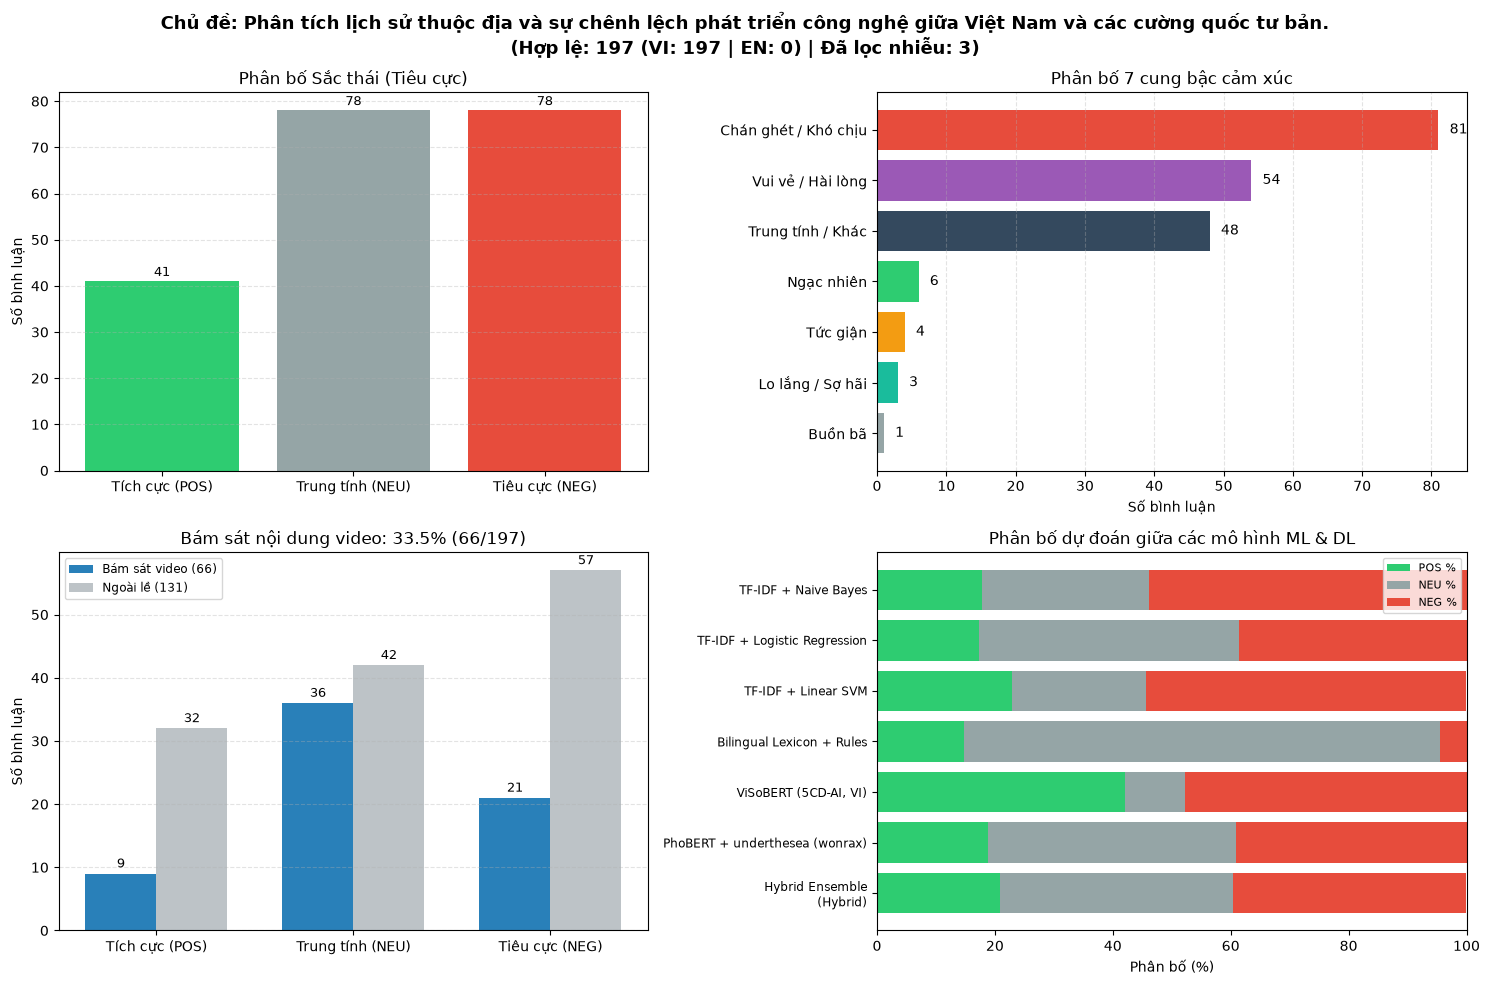

In [5]:
# === DASHBOARD TRỰC QUAN HÓA ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (không vẽ dashboard).")
else:
    summary = report.get("sentiment_summary") or {}
    if summary.get("total_valid_comments", 0) > 0:
        exported = report.get("exported_files", {})
        chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
        fig = plot_sentiment_dashboard(report, save_path=chart_path)
        plt.show()
    else:
        print("Không có bình luận hợp lệ để vẽ dashboard.")